In [255]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint

sns.set_style("whitegrid")
%matplotlib inline
sys.path.append("../")

Dataset com dados de transações e marcações de fraude de um período de dois anos (2019 e 2020) com dados de 
* lojistas ("store_name" como identificador e segmentação do CNPJ "vertical")
* clientes (data de nascimento, profissão, cidade e estado, **não há coluna identificadora para cliente**)
* transação (valor da transação, dispositivo, bandeira do cartão)
* geolocalização do lojista e do comprador

# OBJETIVO DO CASE
Criar um score de risco por transação, com base nos dados apresentados, considerando os impactos financeiros de cada decisão, apresentados na proposta do case, a saber:
* Falso Negativo (FN - Fraude Não Detectada): A transação é aprovada, mas era fraude. Custo = 100% do amount + Taxa Operacional de Chargeback (ex: R$ 15,00).
* Falso Positivo (FP - Cliente Legítimo Rejeitado): A transação legítima é bloqueada. Custo = Margem Financeira Perdida (ex: 10% do amount) + Custo Operacional de Análise Manual.
* Verdadeiro Positivo (TP - Fraude Bloqueada): Fraude evitada com sucesso.
* Verdadeiro Negativo (TN - Venda Legítima Aprovada): Receita gerada com sucesso.


In [275]:
raw = pd.read_csv('../data/nuvem_fraud_dataset.csv', delimiter=';')
raw.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,"107,23",Mobile,Master Card,Orient,WA,48|8878,-118|2105,149,'Special educational needs teacher',1978-06-21 00:00:00+00:00,49|159047,-118|186462,0
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,"220,11",Mobile,Amex,Malad City,ID,42|1808,-112|262,4154,'Nature conservation officer',1962-01-19 00:00:00+00:00,43|150704,-112|154481,0
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,"96,29",Mobile,Amex,Grenada,CA,41|6125,-122|5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41|65752,-122|230347,0
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,"7,77",Mobile,Visa,High Rolls Mountain Park,NM,32|9396,-105|8189,899,'Naval architect',1967-08-30 00:00:00+00:00,32|863258,-106|520205,0
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,"6,85",Web,Master Card,Freedom,WY,43|0172,-111|0292,471,"'Education officer, museum'",1967-08-02 00:00:00+00:00,43|753735,-111|454923,0


In [276]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 341519 entries, 0 to 341518
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   created_at       341519 non-null  str  
 1   store_name       341519 non-null  str  
 2   vertical         341519 non-null  str  
 3   amount           341519 non-null  str  
 4   device           341519 non-null  str  
 5   card_brand       341519 non-null  str  
 6   city             341519 non-null  str  
 7   state            340576 non-null  str  
 8   lat              341308 non-null  str  
 9   long             341197 non-null  str  
 10  city_population  341519 non-null  int64
 11  job              341519 non-null  str  
 12  date_of_birth    341519 non-null  str  
 13  store_lat        341519 non-null  str  
 14  store_long       341519 non-null  str  
 15  is_fraud         341519 non-null  int64
dtypes: int64(2), str(14)
memory usage: 41.7 MB


In [277]:
duplicate_mask = raw.duplicated()

print(f"Duplicate rows: {duplicate_mask.sum()}")
raw.loc[duplicate_mask].head()

Duplicate rows: 1912


,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud
339607,2019-01-01 01:41:39+00:00,'Pacocha-Bauch',shopping_pos,"2,1",Web,Visa,Grenada,CA,41|6125,-122|5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41|096733,-122|623454,0
339608,2019-01-01 01:50:31+00:00,"'Reilly, Heaney and Cole'",gas_transport,"67,91",Mobile,Visa,Fields Landing,CA,40|7268,-124|2174,276,"'Scientist, audiological'",1929-05-06 00:00:00+00:00,41|137569,-123|63216,0
339609,2019-01-01 02:06:56+00:00,'Bradtke PLC',grocery_pos,"78,13",Web,Visa,Louisiana,MO,39|4336,-91|0664,4593,"'Teacher, early years/pre'",1940-11-11 00:00:00+00:00,40|247129,-91|699005,0
339610,2019-01-01 02:08:13+00:00,"'Zieme, Bode and Dooley'",gas_transport,"52,67",Mobile,Master Card,Kansas City,MO,38|9621,-94|5959,545147,'Counsellor',1987-11-18 00:00:00+00:00,39|662816,-93|712244,0
339611,2019-01-01 02:08:48+00:00,'Hills-Witting',shopping_net,"2,11",Mobile,Visa,Mesa,ID,44|6255,-116|4493,129,'Cartographer',1965-12-15 00:00:00+00:00,44|710102,-117|229968,0


In [278]:
raw = raw.drop_duplicates()

In [279]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 339607 entries, 0 to 339606
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   created_at       339607 non-null  str  
 1   store_name       339607 non-null  str  
 2   vertical         339607 non-null  str  
 3   amount           339607 non-null  str  
 4   device           339607 non-null  str  
 5   card_brand       339607 non-null  str  
 6   city             339607 non-null  str  
 7   state            338664 non-null  str  
 8   lat              339396 non-null  str  
 9   long             339285 non-null  str  
 10  city_population  339607 non-null  int64
 11  job              339607 non-null  str  
 12  date_of_birth    339607 non-null  str  
 13  store_lat        339607 non-null  str  
 14  store_long       339607 non-null  str  
 15  is_fraud         339607 non-null  int64
dtypes: int64(2), str(14)
memory usage: 41.5 MB


A partir da data dos eventos (transações), cria-se as colunas cohort("safra") e do dia a partir da coluna "created_at". essas informações serão usadas posteriormente para investigações exploratórias e na segmentação das observações para modelagem

In [280]:
raw['amount'] = pd.to_numeric(raw["amount"].astype(str).str.replace(",", ".", regex=False))

raw["cohort"] = pd.to_datetime(raw["created_at"], utc=True).dt.strftime("%Y-%m")
raw["day"] = pd.to_datetime(raw["created_at"], utc=True).dt.strftime("%Y-%m-%d")


Além desses campos, cria-se um id único para cada transação, a partir do dataset ordenado

In [281]:
raw = raw.reset_index(drop=True)
raw["row_orig"] = raw.index
raw = raw.sort_values(["created_at", "row_orig"]).reset_index(drop=True).drop(["row_orig"], axis=1)
raw["txn_id"] = raw.index


---

Avaliando o perfil de fraudes (taxa de fraude e perda financeira) ao longo do período observado, vemos que há uma taxa média de fraude de 0.5% das transações no período, com uma média de perda em US$39 mil dólares/mês.

No início do período observado a perda estava na máxiam histórica e houve uma queda abrupta nas fraudes no final do primeiro semestre, seguida de um leve aumento em agosto de 2019. a mesma oscilação padrão ocorreu entre o final de 2019 e inicio de 2020, provavelmente devido a atualização das políticas de prevenção a fraude seguida de mudança de modus operandi de fraude.

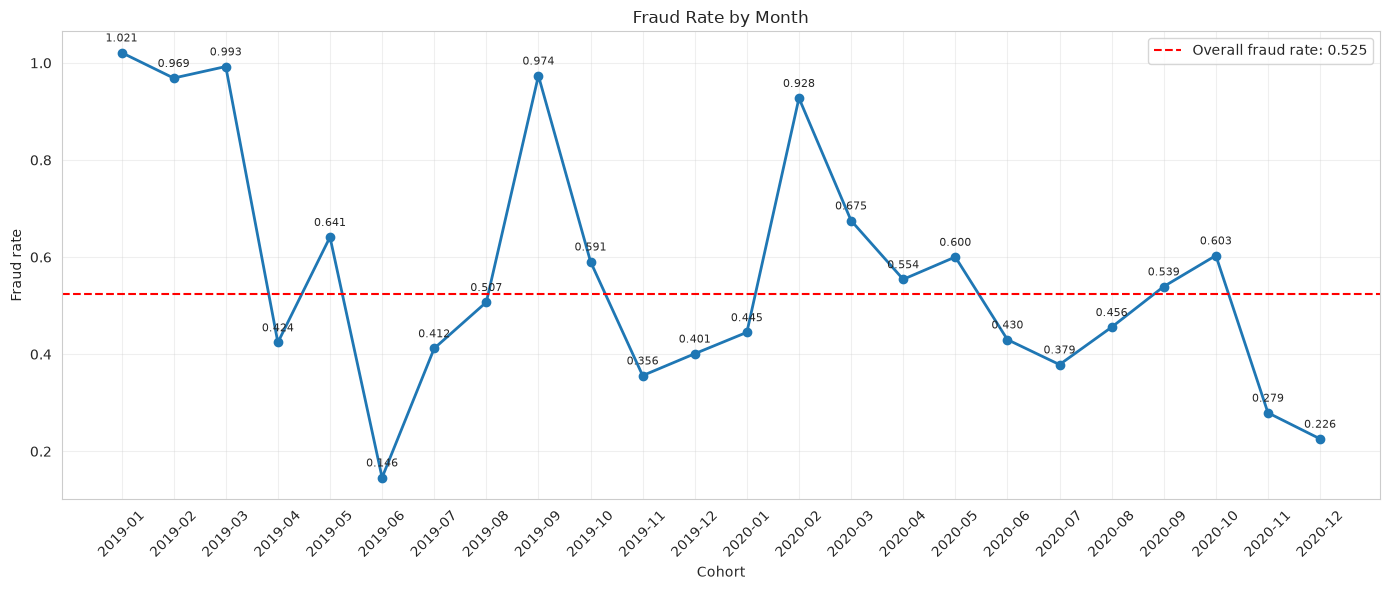

In [282]:
monthly_fraud = raw.groupby("cohort")["is_fraud"].mean().sort_index() * 100
overall_fraud_rate = raw["is_fraud"].mean() * 100

x = monthly_fraud.index.astype(str).tolist()
y = monthly_fraud.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(x, y, marker="o", linewidth=2)

for i, (month, rate) in enumerate(monthly_fraud.items()):
    ax.annotate(
        f"{rate:.3f}",
        (x[i], float(rate)),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )

ax.set_title("Fraud Rate by Month")
ax.set_xlabel("Cohort")
ax.set_ylabel("Fraud rate")
ax.axhline(
    overall_fraud_rate,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall fraud rate: {overall_fraud_rate:.3f}",
)
ax.legend(loc="upper right")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

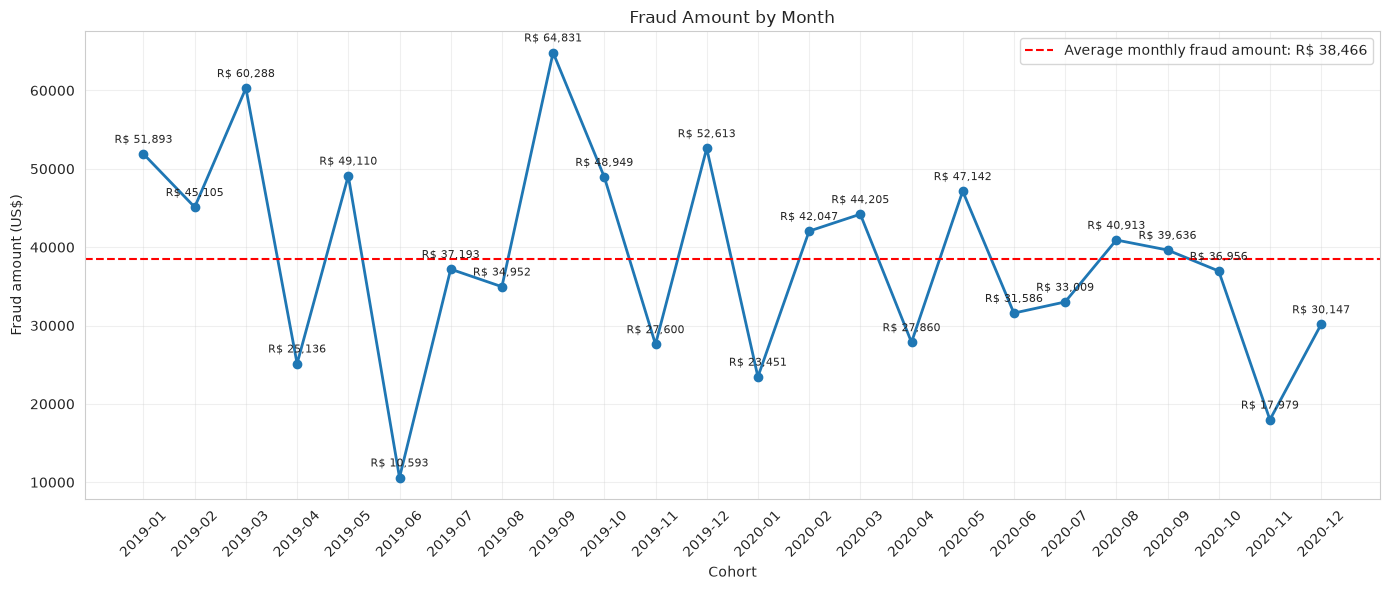

In [283]:
amount_num = pd.to_numeric(
    raw["amount"].astype(str).str.replace(",", ".", regex=False)
)

monthly_fraud_amount = (
    raw.loc[raw["is_fraud"].eq(1)]
    .assign(amount_num=amount_num)
    .groupby("cohort")["amount_num"]
    .sum()
    .reindex(monthly_fraud.index, fill_value=0)
)

average_monthly_fraud_amount = monthly_fraud_amount.mean()
x = monthly_fraud_amount.index.astype(str).tolist()
y = monthly_fraud_amount.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(x, y, marker="o", linewidth=2)

for i, amount in enumerate(y):
    ax.annotate(
        f"R$ {amount:,.0f}",
        (x[i], amount),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )

ax.set_title("Fraud Amount by Month")
ax.set_xlabel("Cohort")
ax.set_ylabel("Fraud amount (US$)")
ax.axhline(
    average_monthly_fraud_amount,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Average monthly fraud amount: R$ {average_monthly_fraud_amount:,.0f}",
)
ax.legend(loc="upper right")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

Analisando os campos do dataset, nota-se que os campo state, vindo do cadastro do cliente e a geolocalização do mesmo apresentam inconsistências no preenchimento do dataset

In [284]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 339607 entries, 0 to 339606
Data columns (total 19 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   created_at       339607 non-null  str    
 1   store_name       339607 non-null  str    
 2   vertical         339607 non-null  str    
 3   amount           339607 non-null  float64
 4   device           339607 non-null  str    
 5   card_brand       339607 non-null  str    
 6   city             339607 non-null  str    
 7   state            338664 non-null  str    
 8   lat              339396 non-null  str    
 9   long             339285 non-null  str    
 10  city_population  339607 non-null  int64  
 11  job              339607 non-null  str    
 12  date_of_birth    339607 non-null  str    
 13  store_lat        339607 non-null  str    
 14  store_long       339607 non-null  str    
 15  is_fraud         339607 non-null  int64  
 16  cohort           339607 non-null  str    
 17  da

In [285]:
pd.DataFrame({
    "null_count": raw.isna().sum(),
    "null_mean": raw.isna().mean(),
})

,null_count,null_mean
created_at,0,0.000000
store_name,0,0.000000
vertical,0,0.000000
amount,0,0.000000
device,0,0.000000
card_brand,0,0.000000
city,0,0.000000
state,943,0.002777
lat,211,0.000621
long,322,0.000948


Nota-se que há um pequeno volume de transações (menos de 0.1% da base) sem informações de geolocalização do cliente. Essas transações se concentraram em dias específicos do período de observação e nenhuma delas foi observada como fraude 

In [286]:
sem_coordenadas = raw[raw[["lat", "long"]].isna().any(axis=1)]

sem_coordenadas.groupby("day")["is_fraud"].agg(["mean", "count"])

,mean,count
day,,
2019-03-29,0.0,31
2019-09-25,0.0,29
2020-02-11,0.0,17
2020-05-30,0.0,260
2020-09-04,0.0,147
2020-12-21,0.0,16


Um padrão mais interessante foi observado para casos em que o campo "state" estava ausente, embora também aparece em dias específicos, quando ausente, foi observado um volume relevante de fraude/chargeback

In [287]:
sem_estado = raw[raw["state"].isna()]

sem_estado.groupby("day")["is_fraud"].agg(["mean", "count"])

,mean,count
day,,
2019-02-28,0.000000,151
2019-03-01,0.035088,57
2019-09-15,0.000000,35
2019-12-23,0.017995,389
2019-12-24,0.010909,275
2020-12-31,0.000000,36


---

In [288]:
def iv_woe_category (df:pd.DataFrame, category:str, target:str) -> pd.DataFrame:
        aux = df.groupby([category, target])['txn_id'].count().unstack()
        aux['bad_rate'] = aux[1]/(aux[1] + aux[0])
        aux['WOE'] = np.log(aux[1]/aux[1].sum()) - np.log(aux[0]/aux[0].sum())
        aux['IV'] = aux['WOE'] * (aux[1]/aux[1].sum() - aux[0]/aux[0].sum() )
        return aux


In [299]:
raw['amount'] = pd.to_numeric(
    raw["amount"].astype(str).str.replace(",", ".", regex=False)
)
raw['log_amount'] = np.log10(raw['amount'],)

In [300]:
raw['amount'].describe()


count    339607.000000
mean         70.577984
std         161.675242
min           1.000000
25%           9.600000
50%          46.460000
75%          83.350000
max       28948.900000
Name: amount, dtype: float64

In [301]:
amount_describe = (
    raw.groupby("is_fraud")["amount"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .rename(index={0: "Não fraude", 1: "Fraude"})
)

amount_describe

,count,mean,std,min,25%,50%,75%,95%,99%,max
is_fraud,,,,,,,,,,
Não fraude,337825.0,68.217523,156.251647,1.00,9.5700,46.250,82.760,193.1460,489.6128,28948.90
Fraude,1782.0,518.065460,389.627409,1.78,214.6775,356.435,884.725,1084.5975,1176.2429,1371.81


In [302]:
raw['log_amount'].describe()


count    339607.000000
mean          1.498323
std           0.604679
min           0.000000
25%           0.982271
50%           1.667079
75%           1.920906
max           4.461632
Name: log_amount, dtype: float64

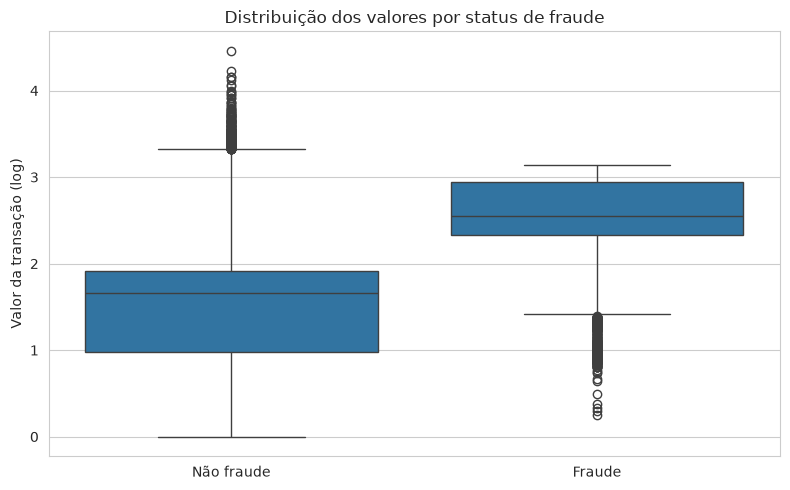

In [303]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=raw, x="is_fraud", y="log_amount", ax=ax)
ax.set_xticks([0, 1], ["Não fraude", "Fraude"])
ax.set_xlabel("")
ax.set_ylabel("Valor da transação (log)")
ax.set_title("Distribuição dos valores por status de fraude")

plt.tight_layout()
plt.show()

In [ ]:













































































































































































































vertical_iv_woe = iv_woe_category(raw, 'vertical', 'is_fraud')
vertical_iv_woe.sort_values('WOE', ascending=False)

is_fraud,0,1,bad_rate,WOE,IV
vertical,,,,,
shopping_net,25998,381,0.014443,1.021816,0.139833
grocery_pos,32299,433,0.013229,0.932738,0.137464
misc_net,16681,217,0.012842,0.902663,0.065349
shopping_pos,30142,187,0.006166,0.162225,0.002549
gas_transport,34936,153,0.004360,-0.186043,0.003266
travel,10289,33,0.003197,-0.497531,0.005940
misc_pos,19962,62,0.003096,-0.529660,0.012869
grocery_net,11328,27,0.002378,-0.794404,0.014602
entertainment,24167,55,0.002271,-0.840618,0.034190


In [298]:
vertical_iv_woe['IV'].sum()

np.float64(0.7042126577288184)

In [215]:
def plot_target_category(df:pd.DataFrame, category:str, target:str) -> None:    
    aux = df.groupby([category, target])['txn_id'].count().unstack()
    aux1 = aux.div(aux.sum(axis=1), axis=0)
    aux1.plot(kind='bar', stacked=True, color=['b','r'])
    plt.legend([0,1], loc=[1,1])
    plt.plot()
   

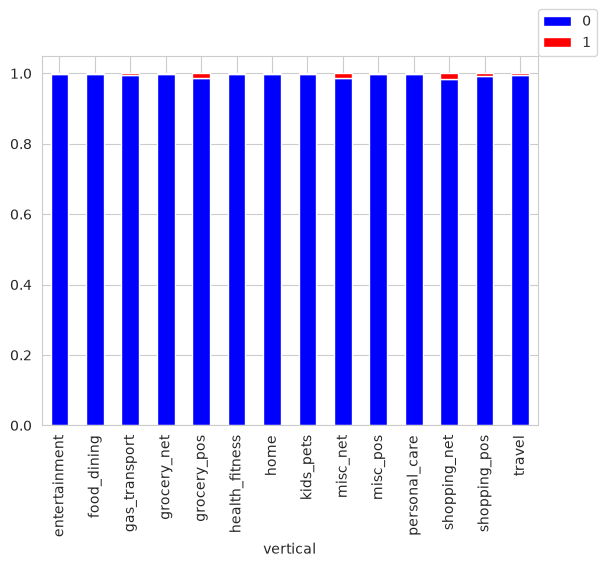

In [216]:
plot_target_category(raw, 'vertical', 'is_fraud')

In [220]:
device_iv_woe = iv_woe_category(raw, 'device', 'is_fraud')
device_iv_woe.sort_values('WOE', ascending=False)

is_fraud,0,1,bad_rate,WOE,IV
device,,,,,
Web,113584,613,0.005368,0.017283,0.000101
Mobile,226133,1189,0.005230,-0.008795,0.000051


In [221]:
bandeira_iv_woe = iv_woe_category(raw, 'card_brand', 'is_fraud')
bandeira_iv_woe.sort_values('WOE', ascending=False)

is_fraud,0,1,bad_rate,WOE,IV
card_brand,,,,,
Master Card,113332,613,0.005380,0.019504,0.000128
Visa,169610,910,0.005337,0.011403,0.000065
Amex,56775,279,0.004890,-0.076424,0.000940


In [222]:
state_iv_woe = iv_woe_category(raw, 'state', 'is_fraud')
state_iv_woe.sort_values('WOE', ascending=False)

is_fraud,0,1,bad_rate,WOE,IV
state,,,,,
AK,2924,65,0.021746,1.436832,0.039774
OR,26290,197,0.007438,0.349413,0.011340
NE,34298,216,0.006258,0.175589,0.003412
CO,19690,115,0.005807,0.100219,0.000614
NM,23354,121,0.005154,-0.019580,0.000026
CA,80336,402,0.004979,-0.054368,0.000682
MO,54811,258,0.004685,-0.115534,0.002039
WA,26986,126,0.004647,-0.123639,0.001145
WY,27738,117,0.004200,-0.225232,0.003719


# Resolução de Identidades

De modo a se obter informação para **cada cliente**, como fator importante para construção do score antifraude e pelo fato de **não possuir um identificador único do dataset**, para esse caso, assumo a construção de um **identificador proxy**, baseado nos dados fornecidos no dataset (data de nascimento, profissão e cidade). Desse modo, foram identificados, **187 clientes únicos** operando em **700** lojistas identificados 

Com esse identificador construído, será possível construir variáveis transacionais com base na movimentação do cliente.

Para implantação em produção do modelo, deverá ser considerada a construção de features baseadas em customer_id e store_id próprios.

In [224]:
raw["customer_id"] = raw.groupby(
    ["date_of_birth", "job", "city"],
    dropna=False
).ngroup()

raw['customer_id'].nunique()

187

Observa-se que para lojas, existem 7 casos onde o mesmo store_name apresenta mais de um "vertical". Assumiu-se que a são canais distintos para o mesmo vendedor (físico e online), **de modo que passei a usar a chave composta para construção do store_id**

In [225]:
inconsistent_stores = (
    raw.groupby(["store_name", "vertical"], dropna=False)
    .size()
    .rename("row_count")
    .reset_index()
    .groupby("store_name")["vertical"]
    .nunique()
    .loc[lambda s: s > 1]
    .index
)

pair_counts = (
    raw.groupby(["store_name", "vertical"], dropna=False)
    .size()
    .rename("row_count")
    .reset_index()
)

pair_counts[pair_counts["store_name"].isin(inconsistent_stores)] \
    .sort_values(["store_name", "vertical"])

,store_name,vertical,row_count
70,'Boyer PLC',misc_pos,372
71,'Boyer PLC',shopping_net,501
106,'Cormier LLC',health_fitness,464
107,'Cormier LLC',shopping_net,524
138,'Dickinson Lt',misc_pos,411
139,'Dickinson Lt',personal_care,487
194,'Gislason Group',misc_pos,442
195,'Gislason Group',travel,212
320,'Kilback LLC',food_dining,441
321,'Kilback LLC',grocery_pos,715


In [127]:
raw["store_id"] = raw.groupby(
    ["store_name", "vertical"],
    dropna=False
).ngroup()

raw['store_id'].nunique()

700

Um ponto de atenção notável com relação às informações das lojas, foi a variação entre store_lat e store_long dentro de cada store_id, sinalizando que as coordenadas apresentadas **não representam a localização do ponto de venda físico/online de forma confiável** . Desse modo, não será utilizado no desenvolvimento da estratégia analítica esse dado, mas para uma versão produtiva desse case, seria interessante incorporar features de IP e geolocalização do cliente  e match com os dados do cliente.

In [157]:
raw.loc[raw['store_id']==1].head(3)

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,...,date_of_birth,store_lat,store_long,is_fraud,cohort,day,customer_id,store_id,store_key_name,store_key_nv
288,2019-01-01 15:47:50+00:00,'Abbott-Steube',personal_care,"111,13",Mobile,Visa,Roseland,NE,40|4591,-98|5551,...,1948-05-31 00:00:00+00:00,40|300769,-98|784576,0,2019-01,2019-01-01,25,1,1,1
1193,2019-01-04 23:13:03+00:00,'Abbott-Steube',personal_care,"100,33",Web,Visa,Carlotta,CA,40|507,-123|9743,...,1951-01-15 00:00:00+00:00,39|578954,-124|964071,0,2019-01,2019-01-04,29,1,1,1
1706,2019-01-06 15:11:16+00:00,'Abbott-Steube',personal_care,"44,88",Mobile,Visa,Issaquah,WA,47|4974,-122|0107,...,1984-02-29 00:00:00+00:00,47|463356,-122|583257,0,2019-01,2019-01-06,139,1,1,1


In [155]:
raw["store_key_name"] = raw.groupby("store_name").ngroup()

raw["store_key_nv"] = raw.groupby(["store_name", "vertical"]).ngroup()
print("lojas por nome:", raw["store_key_name"].nunique(), "| por nome+vertical:", raw["store_key_nv"].nunique())

lojas por nome: 693 | por nome+vertical: 700


---

Testando split (fazer outro notebook)

In [28]:
df = raw
df["ym"] = pd.to_datetime(df["created_at"], utc=True).dt.strftime("%Y-%m")
conds = [df.ym < "2019-02", df.ym.between("2019-02", "2020-04"), df.ym == "2020-05",
         df.ym.between("2020-06", "2020-08"), df.ym == "2020-09", df.ym >= "2020-10"]
df["split"] = np.select(
    conds,
    ["warmup", "train", "gap1", "valid", "gap2", "test"],
    default="unassigned",
)
print(df.groupby("split")["is_fraud"].agg(["size", "sum", "mean"]))

          size   sum      mean
split                         
gap1     13494    81  0.006003
gap2     12793    69  0.005394
test     51557   171  0.003317
train   203934  1159  0.005683
valid    48135   203  0.004217
warmup   11606   119  0.010253
